# Vaste offsetkeuzes na epoch 50 — voortzetting tot epoch 100

**Onderzoeksvraag:** blijft het voordeel van vaste extra exponentoffsets behouden wanneer de gewichten verder trainen tot epoch 100?

De eerste 50 epochs zijn gemeenschappelijk. Daarna zijn de extra offsetkeuzes per MX-blok vastgezet. De korte pilot heeft **epochs 51–55** al uitgevoerd. Deze proef herstelt dat bevroren checkpoint na **epoch 55** en voert uitsluitend **epochs 56–100** uit. De historische vergelijking is de bestaande dynamische training, waarin de offsets verder leerden.

De gewichten blijven leren via **E4M3 → E2M3 → E2M1**; activaties blijven **A32** en mastergewichten **FP32**. E4M3-broncodes en bronschalen blijven uit de actuele gewichten bepaald. De oorspronkelijke LR-dalingen na epochs 75 en 90 blijven behouden.

Deze notebook leest opgeslagen resultaten, laadt geen model of checkpoint en start geen training. Alleen `SAVE_FIGURES = True` bewaart figuren in een nieuwe analysemap.

In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_freeze_offsets_e50_reference100\\20261025_183915_084406_freeze100_run')
SAVE_FIGURES = False  # True: figuren in een nieuwe analysemap.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
if not helper_path.is_file():
    raise FileNotFoundError('Stel RUN_DIR in op de resultatenmap van de voortzetting tot epoch 100: ' + str(helper_path.parent))
helper_name = '_mx_freeze_offsets_e50_reference100_analysis'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(ns.diagnostics_table(run))

**Voortzetting tot epoch 100 voltooid — rapportstatus PASS.**

Laatste gemeten epoch: 100. De geschiedenis bevat de vijf geërfde bevroren pilotepochs 51–55 en 45 nieuw gemeten epochs vanaf 56. Historische referentie: gecontroleerd. Vaste offsetkeuzes: bevestigd.

**Hoofdvergelijking:** alle drie precisies op epoch 100. **Aanvullend:** het E4M3-beste checkpoint na de freeze (51–100) en het globale E4M3-beste checkpoint (1–100). Iedere selectie gebruikt voor alle drie precisies dezelfde epoch. Een globaal checkpoint vóór epoch 51 hoort bij de gemeenschappelijke voorfase.

,Onderdeel,Afspraak
0,Hervatpunt,Bestaande bevroren checkpoint na epoch 55; mod...
1,Nieuwe training,Alleen epochs 56–100; de bevroren pilot 51–55 ...
2,Freeze-anker,Extra offset per blok blijft die van het check...
3,Blokverdeling,1654×32; 2426×64
4,Historische vergelijking,Oorspronkelijke dynamische training 1–100; gee...
5,E4M3-bronschaal,Wordt telkens uit de actuele gewichten bepaald
6,Gewichten / activaties,FP32-master; E4M3 → E2M3 → E2M1; activaties A32
7,Gewichts-LR,"56–75: 0,0001; 76–90: 0,00001; 91–100: 0,000001"
8,Schaal-LR,0; theta en harde offsetkeuzes exact vast; gra...
9,Primair,Alle drie testaccuracies op epoch 100


,Niveau,Melding
0,INTERPRETATIE,Historische dynamische controle; geen nieuwe c...


## Freeze-anker, pilot en nieuwe voortzetting

Voor ieder blok geldt nog steeds:

$$E_{\mathrm{laag},b}(t) = E_{\mathrm{E4M3},b}(t) + k_b.$$

De extra offset $k_b$ blijft de keuze na epoch 50: **5 voor ×32** of **6 voor ×64**. De bronschaal kan veranderen wanneer de gewichten veranderen.

De theta-leerstap blijft nul. De bestaande schaalgradient en Adam-momentupdates blijven voor deze diagnose berekend. We meten hiermee het accuracy-effect van vaste keuzes; dit is geen meting van een geoptimaliseerde trainingsbesparing.

In de figuur is **51–55 de geërfde pilot** en **56–100 de nieuwe voortzetting**. De verticale hulplijnen staan na epoch 55 en bij de LR-overgangen na epochs 75 en 90.

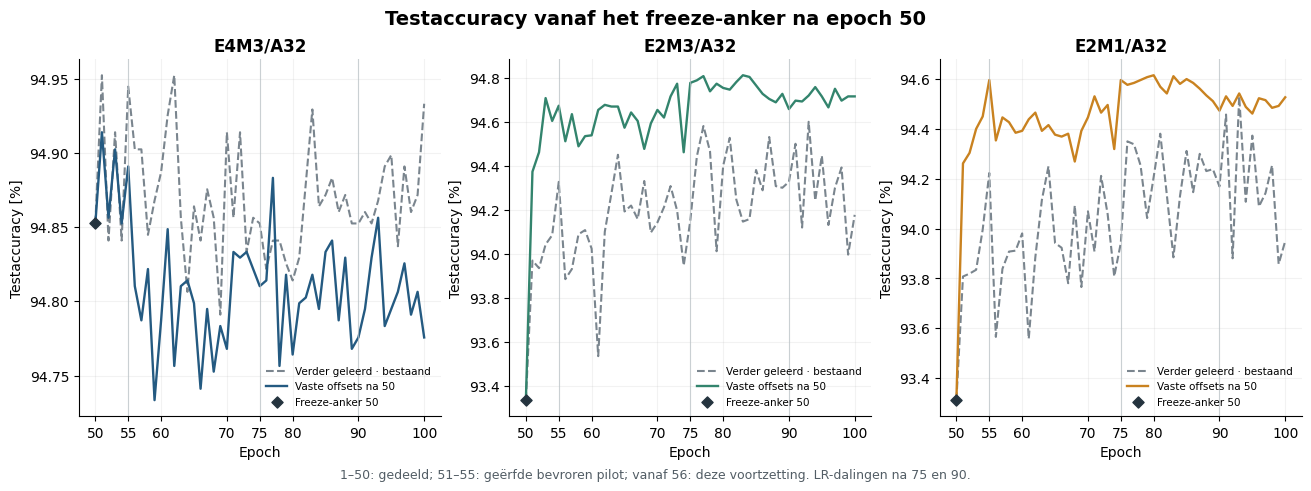

In [3]:
figures['accuracy_after_freeze'] = ns.plot_accuracy_curves(run)
display(figures['accuracy_after_freeze'])
plt.close(figures['accuracy_after_freeze'])

## Primair vergelijkingspunt: epoch 100

We vergelijken de drie precisies op **dezelfde epoch 100**. Dit is het vooraf gekozen hoofdcriterium. De groep hieronder verschijnt pas wanneer epoch 100 werkelijk is gemeten.

Het verschil is **vaste offset minus verder geleerde offset**, uitgedrukt in procentpunt.

,Variant,Selectie,Epoch,Fase,Precisie,Testaccuracy [%],Correct,Testbeelden
0,Offset verder geleerd (bestaand),Primair: epoch 100,100,Verder geleerd — historische run,E4M3/A32,94.933159,24713,26032
1,Offset verder geleerd (bestaand),Primair: epoch 100,100,Verder geleerd — historische run,E2M3/A32,94.176398,24516,26032
2,Offset verder geleerd (bestaand),Primair: epoch 100,100,Verder geleerd — historische run,E2M1/A32,93.949754,24457,26032
3,Offset vast na epoch 50,Primair: epoch 100,100,Bevroren voortzetting 56–100,E4M3/A32,94.775661,24672,26032
4,Offset vast na epoch 50,Primair: epoch 100,100,Bevroren voortzetting 56–100,E2M3/A32,94.714198,24656,26032
5,Offset vast na epoch 50,Primair: epoch 100,100,Bevroren voortzetting 56–100,E2M1/A32,94.525968,24607,26032


,Epoch,Precisie,Vaste offset [%],Verder geleerd [%],Verschil [procentpunt],Verschil correct voorspeld
147,100,E2M1,94.525968,93.949754,0.576214,150
148,100,E2M3,94.714198,94.176398,0.537800,140
149,100,E4M3,94.775661,94.933159,-0.157498,-41


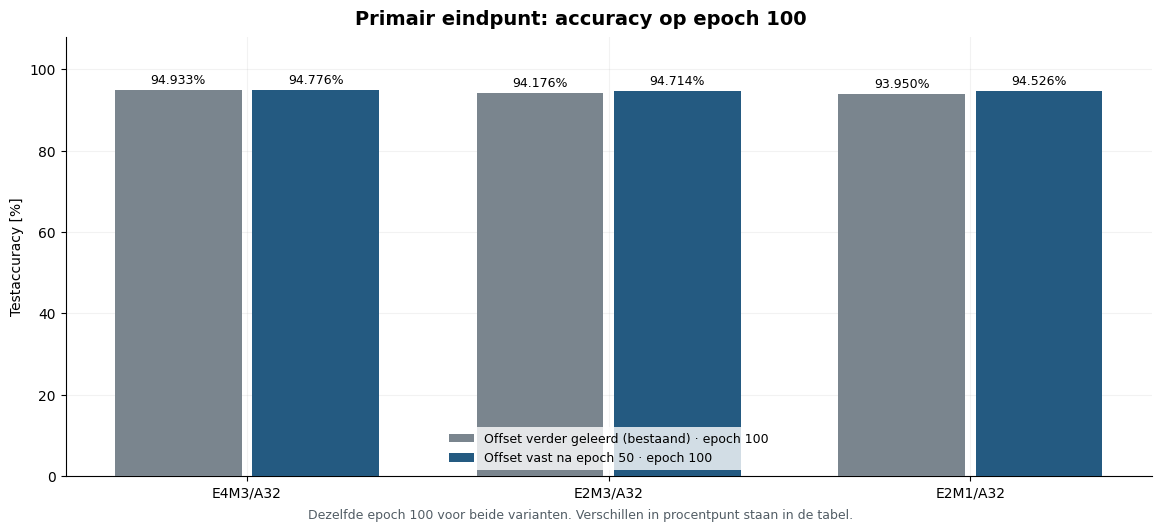

In [4]:
display(ns.checkpoint_table(run, 'endpoint').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
delta = ns.delta_table(run)
if not delta.empty:
    display(delta.loc[delta.Epoch.eq(100)].drop(columns=['weight_bits']).round(6))
figures['accuracy_epoch100'] = ns.plot_checkpoint_accuracy(run, 'endpoint')
display(figures['accuracy_epoch100'])
plt.close(figures['accuracy_epoch100'])

## Aanvullend: E4M3-beste checkpoint na de freeze

Per variant kiezen we het **eerste maximum van de E4M3-testaccuracy binnen epochs 51–100**. Vervolgens tonen we E4M3, E2M3 en E2M1 op precies diezelfde epoch. De twee varianten mogen elk een andere geselecteerde epoch hebben.

Deze selectie beschrijft specifiek de fase na het vastzetten van de offsetkeuzes. Bij een gedeeltelijke run wordt voor beide varianten hetzelfde gemeten deel van 51–100 gebruikt. Selectie op de officiële testset blijft een geselecteerde score en is geen onafhankelijke validatieschatting.

,Variant,Selectie,Epoch,Fase,Precisie,Testaccuracy [%],Correct,Testbeelden
0,Offset verder geleerd (bestaand),E4M3-best na freeze: 51–100,51,Verder geleerd — historische run,E4M3/A32,94.952366,24718,26032
1,Offset verder geleerd (bestaand),E4M3-best na freeze: 51–100,51,Verder geleerd — historische run,E2M3/A32,93.968961,24462,26032
2,Offset verder geleerd (bestaand),E4M3-best na freeze: 51–100,51,Verder geleerd — historische run,E2M1/A32,93.807621,24420,26032
3,Offset vast na epoch 50,E4M3-best na freeze: 51–100,51,Bevroren pilot 51–55 — geërfd,E4M3/A32,94.913952,24708,26032
4,Offset vast na epoch 50,E4M3-best na freeze: 51–100,51,Bevroren pilot 51–55 — geërfd,E2M3/A32,94.372311,24567,26032
5,Offset vast na epoch 50,E4M3-best na freeze: 51–100,51,Bevroren pilot 51–55 — geërfd,E2M1/A32,94.260910,24538,26032


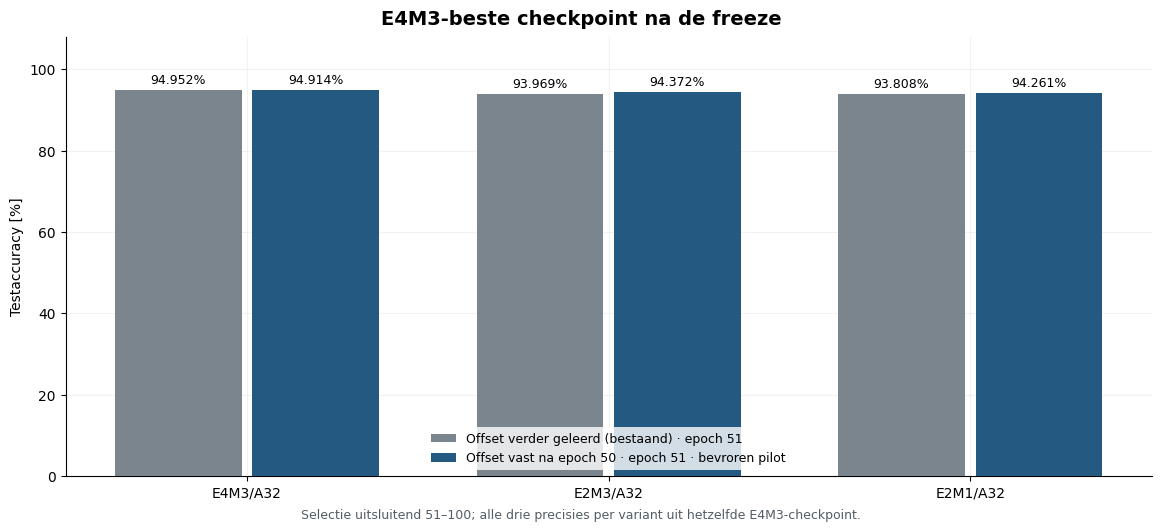

In [5]:
display(ns.checkpoint_table(run, 'postfreeze').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
figures['accuracy_best_E4_after_freeze'] = ns.plot_checkpoint_accuracy(run, 'postfreeze')
display(figures['accuracy_best_E4_after_freeze'])
plt.close(figures['accuracy_best_E4_after_freeze'])

## Gebruikelijke globale E4M3-selectie over epochs 1–100

We behouden daarnaast het overzicht volgens de gebruikelijke selectie over de **volledige training**. Voor de vaste-offsetvariant bestaat die geschiedenis uit de gemeenschappelijke epochs 1–50 en de bevroren epochs 51–100.

Een globaal beste checkpoint kan uit de **gemeenschappelijke voorfase vóór de freeze** komen. Dat checkpoint wordt expliciet zo gelabeld. De scores ervan beschrijven dan het model van vóór de ingreep en kunnen niet als resultaat van de bevroren voortzetting worden geïnterpreteerd. Alle drie precisies komen ook hier uit één gedeelde E4M3-selectie per variant.

,Variant,Selectie,Epoch,Fase,Precisie,Testaccuracy [%],Correct,Testbeelden
0,Offset verder geleerd (bestaand),Globaal E4M3-best: 1–100,34,Gemeenschappelijke voorfase — vóór freeze,E4M3/A32,95.013829,24734,26032
1,Offset verder geleerd (bestaand),Globaal E4M3-best: 1–100,34,Gemeenschappelijke voorfase — vóór freeze,E2M3/A32,93.192993,24260,26032
2,Offset verder geleerd (bestaand),Globaal E4M3-best: 1–100,34,Gemeenschappelijke voorfase — vóór freeze,E2M1/A32,93.592502,24364,26032
3,Offset vast na epoch 50,Globaal E4M3-best: 1–100,34,Gemeenschappelijke voorfase — vóór freeze,E4M3/A32,95.013829,24734,26032
4,Offset vast na epoch 50,Globaal E4M3-best: 1–100,34,Gemeenschappelijke voorfase — vóór freeze,E2M3/A32,93.192993,24260,26032
5,Offset vast na epoch 50,Globaal E4M3-best: 1–100,34,Gemeenschappelijke voorfase — vóór freeze,E2M1/A32,93.592502,24364,26032


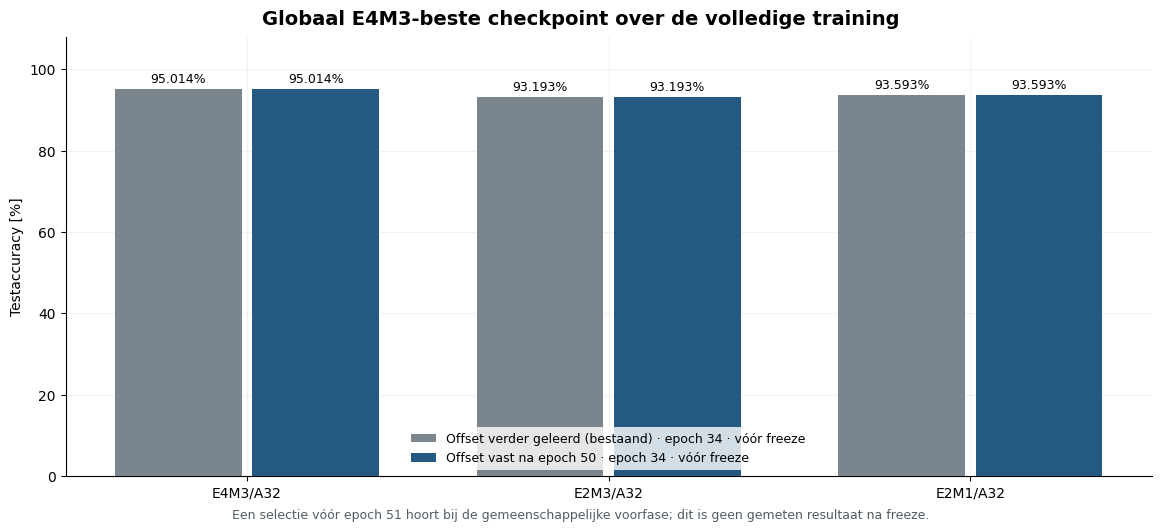

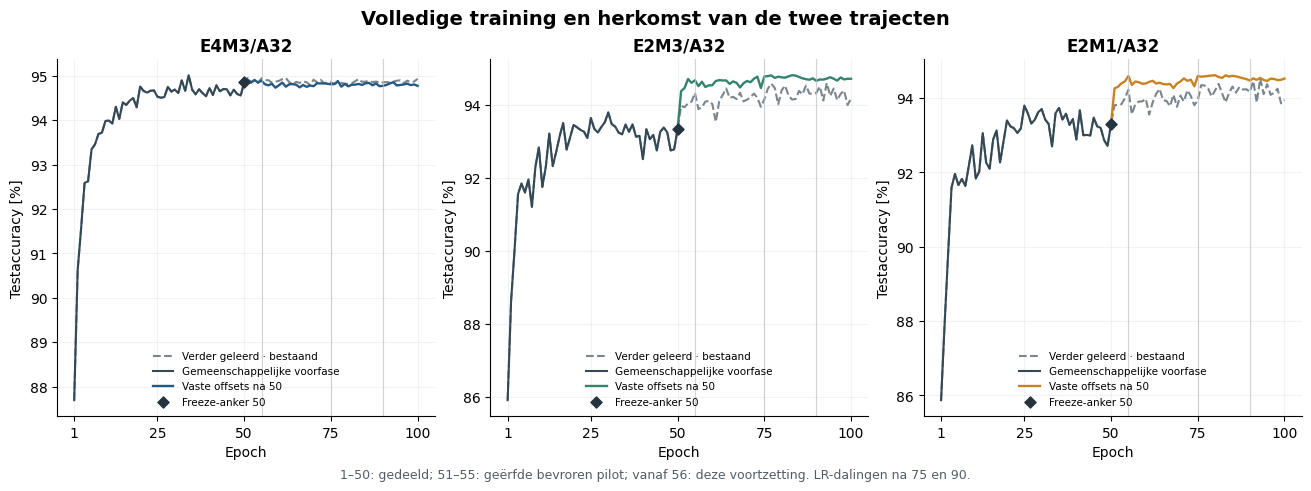

In [6]:
display(ns.checkpoint_table(run, 'global').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
figures['accuracy_best_E4_global'] = ns.plot_checkpoint_accuracy(run, 'global')
display(figures['accuracy_best_E4_global'])
plt.close(figures['accuracy_best_E4_global'])
figures['accuracy_full_history'] = ns.plot_accuracy_curves(run, full_history=True)
display(figures['accuracy_full_history'])
plt.close(figures['accuracy_full_history'])

## Accuracyverschillen gedurende de bevroren fase

Voor elke epoch en precisie gebruiken we de bijbehorende meting uit de bestaande dynamische training. De geërfde pilot en de nieuwe voortzetting vormen samen één traject. Opeenvolgende epochs zijn geen onafhankelijke herhalingen.

Positieve verschillen betekenen hogere accuracy met vaste offsets. De tabel bevat de hoofdmeetpunten en de laatste tien gemeten epochs; de figuur toont alle gemeten epochs vanaf het freeze-anker.

,Epoch,Precisie,Vaste offset [%],Verder geleerd [%],Verschil [procentpunt],Verschil correct voorspeld
0,51,E2M1,94.260910,93.807621,0.453288,118
1,51,E2M3,94.372311,93.968961,0.403350,105
2,51,E4M3,94.913952,94.952366,-0.038414,-10
12,55,E2M1,94.595114,94.222495,0.372618,97
13,55,E2M3,94.671942,94.326214,0.345728,90
14,55,E4M3,94.890903,94.944683,-0.053780,-14
72,75,E2M1,94.595114,93.942071,0.653042,170
73,75,E2M3,94.775661,94.149508,0.626152,163
74,75,E4M3,94.810234,94.852489,-0.042256,-11
75,76,E2M1,94.575907,94.349262,0.226644,59


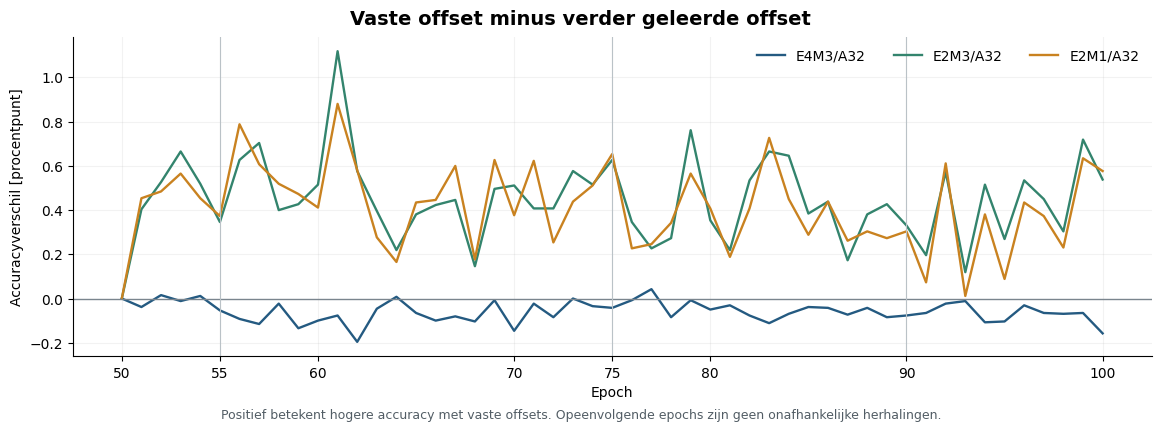

In [7]:
if not delta.empty:
    important_epochs = {51, 55, 75, 76, 90, 91, 100}
    if run.last_epoch is not None:
        important_epochs.update(range(max(51, run.last_epoch - 9), run.last_epoch + 1))
    display(delta.loc[delta.Epoch.isin(important_epochs)].drop(columns=['weight_bits']).round(6))
figures['accuracy_delta'] = ns.plot_accuracy_delta(run)
display(figures['accuracy_delta'])
plt.close(figures['accuracy_delta'])

## Controle: vaste keuzes gedurende alle bevroren epochs

De opgeslagen theta-waarden moeten exact gelijk blijven aan het checkpoint na epoch 50. De runner controleert dit na iedere optimizerstap. Zowel de geërfde pilot als de nieuwe voortzetting moeten **nul theta-wijzigingen en nul offsetwisselingen** tonen.

Een constant totaal aandeel ×32 is op zichzelf onvoldoende: tegengestelde wisselingen van verschillende blokken zouden elkaar in dat totaal kunnen opheffen. Daarom worden zowel de volledige blokstaat als de wisseltellers gecontroleerd. Een wisselteller telt gebeurtenissen; hetzelfde blok kan meerdere keren meetellen.

,Epoch,Blokken,×32,×64,Gewijzigde proxy’s,Offsetwissels tijdens epoch,Blokken met offsetwissel,Aandeel ×32 [%]
0,51,4080,1654,2426,0,0,0,40.539216
4,55,4080,1654,2426,0,0,0,40.539216
24,75,4080,1654,2426,0,0,0,40.539216
25,76,4080,1654,2426,0,0,0,40.539216
39,90,4080,1654,2426,0,0,0,40.539216
40,91,4080,1654,2426,0,0,0,40.539216
49,100,4080,1654,2426,0,0,0,40.539216


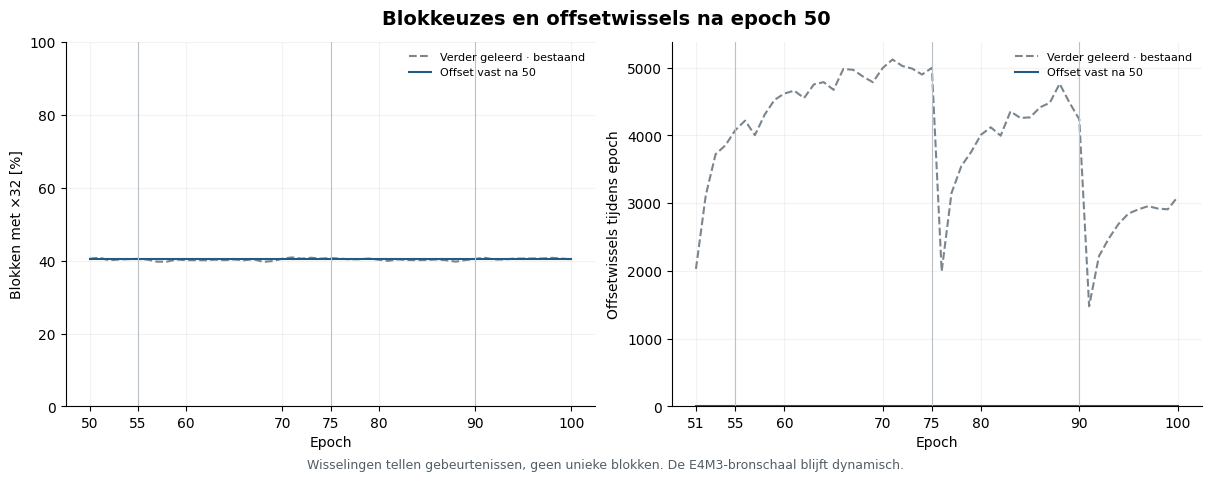

In [8]:
freeze = ns.freeze_table(run)
if not freeze.empty:
    display(freeze.loc[freeze.Epoch.isin({51, 55, 75, 76, 90, 91, 100, run.last_epoch})].round(6))
figures['scale_choices_and_switches'] = ns.plot_scale_choices(run)
display(figures['scale_choices_and_switches'])
plt.close(figures['scale_choices_and_switches'])

## Trainingsobjectieven

E4M3 gebruikt harde cross-entropy. E2M3 en E2M1 gebruiken ieder zachte cross-entropy met de vorige precisie als losgekoppelde leraar. Vergelijk de twee trajecten per precisie; de drie trainingsobjectieven zijn onderling verschillend.

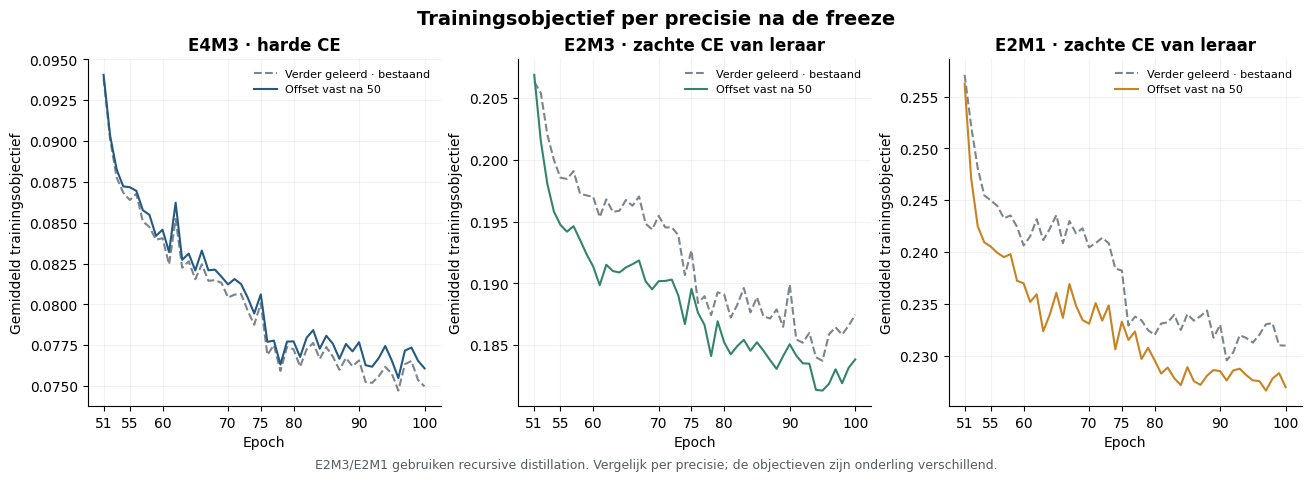

In [9]:
figures['training_objectives'] = ns.plot_objectives(run)
display(figures['training_objectives'])
plt.close(figures['training_objectives'])

## Gemeten duur

De epochtijden omvatten training, evaluatie, controles en checkpointschrijven. **Epochs 51–55 zijn geërfd uit de pilot** en **vanaf epoch 56 is nieuw uitgevoerd**. De samenvatting hieronder houdt die fasen uit elkaar.

Andere uitvoeringsomstandigheden en hervatkosten kunnen de tijd beïnvloeden. Deze FP32-emulatie van MX-gewichten meet geen native MX-versnelling of energieverbruik.

,Variant,Fase,Gemeten_epochs,Totale_seconden,Mediane_epochseconden
0,Offset vast na epoch 50,Geërfde pilot,5,308.475,60.456
1,Offset vast na epoch 50,Nieuwe voortzetting,45,3087.192,69.318
2,Offset verder geleerd (bestaand),Historisch,50,3874.912,68.721


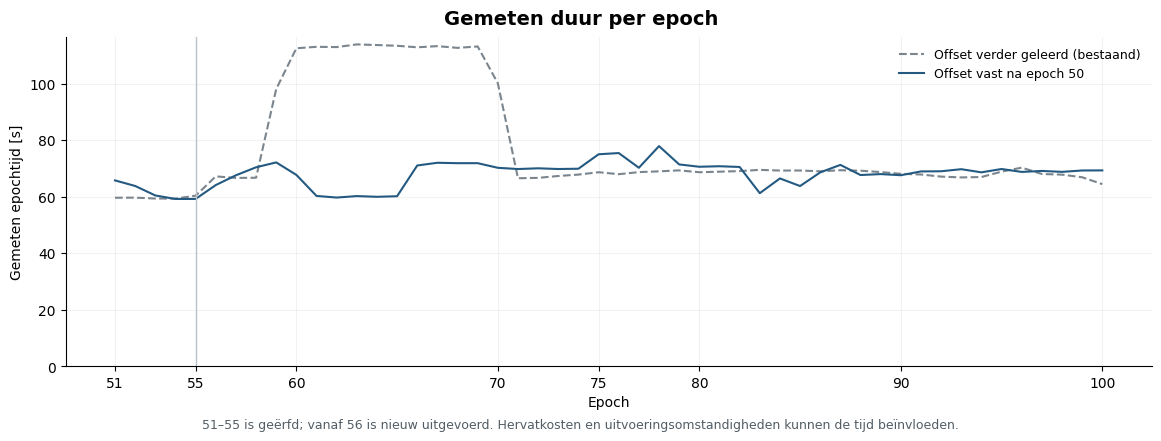

In [10]:
times = ns.timing_table(run)
if not times.empty:
    display(times.groupby(['Variant', 'Fase'], as_index=False).agg(
        Gemeten_epochs=('Epoch', 'count'),
        Totale_seconden=('Gemeten epochtijd [s]', 'sum'),
        Mediane_epochseconden=('Gemeten epochtijd [s]', 'median')
    ).round(3))
figures['epoch_timing'] = ns.plot_timing(run)
display(figures['epoch_timing'])
plt.close(figures['epoch_timing'])

## Interpretatie en herkomst

- Begin met **epoch 100** en de drie accuracyverschillen tegenover de bestaande dynamische training.
- Bekijk de ontwikkeling over de hele bevroren fase, inclusief de oorspronkelijke LR-overgangen na 75 en 90.
- De E4M3-selectie na de freeze en de globale selectie beantwoorden verschillende vragen. Let bij de globale selectie op de aanduiding vóór/na freeze.
- De geselecteerde scores komen uit de officiële testset. Er is geen afzonderlijke validatieset.
- De bestaande CUDA-instellingen garanderen geen bitexacte herhaling. Eén voortzetting geeft geen schatting van de spreiding tussen runs.
- Deze proef bepaalt niet of epoch 50 het optimale freezemoment is en meet geen geoptimaliseerde besparing van schaaltraining.

De historische dynamische run staat onder `dynamic_reference`; de ongewijzigde pilot onder `pilot_reference`. De notebook verifieert de beschikbare bestandschecksums, de geërfde eerste vijf bevroren epochs, het herstel van checkpoint 55, de voorbeeldvolgorde, de vaste blokkeuzes en de consistentie van JSON/CSV/selecties. Binaire `.pt`-exports worden hier niet opnieuw ingeladen; de bijbehorende controles zijn runtimegerapporteerd.

In [11]:
if SAVE_FIGURES:
    destination = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', destination)
else:
    print('Alleen gelezen en weergegeven; bestaande resultaten zijn ongewijzigd.')

Alleen gelezen en weergegeven; bestaande resultaten zijn ongewijzigd.
